# Finite elements: assembling a load vector

A finite-element mesh is a list of triangles, each naming three nodes. To assemble a load vector, every triangle
hands a share of its load to each of its three corners, and a node shared by several triangles collects them all.
In hawk that is one lane per (triangle, corner) and one `hawk.scatter` into the nodes.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [Across lanes](../across_lanes)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import plot_style, show
plot_style()

## A mesh and its connectivity

Cut the unit square into triangles and nudge the interior nodes so the mesh is not a regular grid. `conn` lists the
three node numbers of each triangle, one after the other.

In [3]:
from nb_helpers import gpu_available
import numpy as np

def make_mesh(side):
    xs, ys = np.meshgrid(np.linspace(0, 1, side + 1), np.linspace(0, 1, side + 1))
    nodes = np.c_[xs.ravel(), ys.ravel()]
    rng = np.random.default_rng(7)
    inner = ((nodes > 0) & (nodes < 1)).all(axis=1)
    nodes[inner] += rng.uniform(-0.15, 0.15, size=(inner.sum(), 2)) / side
    tri = []
    for j in range(side):
        for i in range(side):
            a = j * (side + 1) + i
            b, c, d = a + 1, a + side + 1, a + side + 2
            tri += [[a, b, d], [a, d, c]]
    return nodes, np.array(tri, dtype=np.int32)

side = 6 if not gpu_available() else 16            # squares per side: a small mesh on a CPU, a larger one on a GPU
nodes, conn = make_mesh(side)
E, N = len(conn), len(nodes)
print(f"{E} triangles, {N} nodes")

512 triangles, 289 nodes


## One lane per corner

The load is a varying source, `f = 2 pi^2 sin(pi x) sin(pi y)`, whose integral over the unit square is exactly 8.
Each triangle takes `f` at its centroid and gives a third of `f * area` to each corner.

`Grid["e", "a":3]` gives every triangle `e` three lanes, one per corner `a`. The last axis is the fastest, so the
three corners of a triangle are neighbouring lanes. In the body:

- `lane.e` and `lane.a` read an axis by its label; `lane[0]` is the slowest axis and `lane[-1]` the fastest;
  `lane.flat` is the lane's number over the whole grid.
- `conn.at(i)` reads the connectivity; `xy[p, 0]` reads node `p`, coordinate 0. On a named-axis `Table`
  the bracket takes one index per declared axis, in order, and means the same as `xy.at(node=p, axis=0)`.
- `hawk.scatter(b)[node] += value` adds into the node; lanes that share a node are combined, never a race.

Each corner lane recomputes its triangle's area and centroid. That is the price of one lane per corner; here it
keeps the lane layout in view.

The kernel fills two outputs in one pass: the load `b`, and `share`, the area share of each node (the load of `f = 1`).

In [4]:
import eagle
import hawk
import hawk.math as m
from hawk import Grid, Index, Mutable, Table

PI = 3.141592653589793

def make_load(n):
    @hawk.kernel
    def load(lane: Grid["e", "a":3], conn: Table[Index], xy: Table["node":n, "axis":2],
             b: Mutable["node":n], share: Mutable["node":n]):
        p = conn.at(lane.e * 3)
        q = conn.at(lane.e * 3 + 1)
        r = conn.at(lane.e * 3 + 2)
        area = 0.5 * ((xy[q, 0] - xy[p, 0]) * (xy[r, 1] - xy[p, 1])
                      - (xy[r, 0] - xy[p, 0]) * (xy[q, 1] - xy[p, 1]))
        cx = (xy[p, 0] + xy[q, 0] + xy[r, 0]) / 3.0
        cy = (xy[p, 1] + xy[q, 1] + xy[r, 1]) / 3.0
        f = 2.0 * PI * PI * m.sin(PI * cx) * m.sin(PI * cy)
        hawk.scatter(b)[conn.at(lane.flat)] += f * m.abs(area) / 3.0
        hawk.scatter(share)[conn.at(lane.flat)] += m.abs(area) / 3.0
    return load

def assemble(nodes, conn):
    out = eagle.deploy(make_load(len(nodes))).run(conn=conn.ravel(), xy=nodes, e=len(conn))
    return out["b"], out["share"]

make_load(N)

<Kernel load slots=6>

`e` is a bare label, so its extent is not fixed in the kernel: you give it by name when you run, `e=len(conn)`. The
other axes carry their size in the declaration.

In [5]:
b, share = assemble(nodes, conn)

# the same assembly in NumPy
p, q, r = (nodes[conn[:, k]] for k in range(3))
area = 0.5 * np.abs((q[:, 0] - p[:, 0]) * (r[:, 1] - p[:, 1]) - (r[:, 0] - p[:, 0]) * (q[:, 1] - p[:, 1]))
c = (p + q + r) / 3.0
f_c = 2 * np.pi**2 * np.sin(np.pi * c[:, 0]) * np.sin(np.pi * c[:, 1])
want = np.zeros(N)
np.add.at(want, conn.ravel(), np.repeat(f_c * area / 3.0, 3))

assert np.allclose(b, want)
assert abs(b.sum() - 8.0) < 0.2                    # the loads add up to the integral of f
print(f"matches NumPy; total load {b.sum():.4f}, exact integral 8")

matches NumPy; total load 8.0180, exact integral 8


## Does it converge?

The loads should add up to the integral of `f`, 8, and the error should fall by about 4 each time the mesh spacing
halves (centroid quadrature is second order).

In [6]:
sizes = (8, 16, 32) if not gpu_available() else (8, 16, 32, 64)
errors = []
for s in sizes:
    nd, cn = make_mesh(s)
    errors.append(abs(assemble(nd, cn)[0].sum() - 8.0))
for s, err in zip(sizes, errors):
    print(f"{s:3d} squares per side: error {err:.1e}")
ratios = [a / b for a, b in zip(errors, errors[1:])]
print("error ratio per halving:", np.round(ratios, 1))
assert errors[-1] < 1e-2 and all(3.0 < ratio < 5.0 for ratio in ratios)

  8 squares per side: error 7.1e-02
 16 squares per side: error 1.8e-02
 32 squares per side: error 4.5e-03
 64 squares per side: error 1.1e-03
error ratio per halving: [3.9 4.  4. ]


## Reading the lane coordinates

The three spellings of a lane's position, on a grid small enough to read. The first kernel returns
`lane.e * 10 + lane[-1]` (triangle, then corner, by label and by position); the second returns the flat lane number.

In [7]:
@hawk.kernel
def where_am_i(lane: Grid["e", "a":3]) -> Index:
    return lane.e * 10 + lane[-1]

@hawk.kernel
def flat_number(lane: Grid["e", "a":3]) -> Index:
    return lane.flat

print(eagle.deploy(where_am_i).run(e=2).reshape(2, 3))
print(eagle.deploy(flat_number).run(e=2).reshape(2, 3))

[[ 0  1  2]
 [10 11 12]]


[[0 1 2]
 [3 4 5]]


## The source, recovered from the load

A nodal load scales with the area around the node, so it mostly shows the mesh. The kernel also gave each node's area share; divide by it: the result is the source at the nodes.


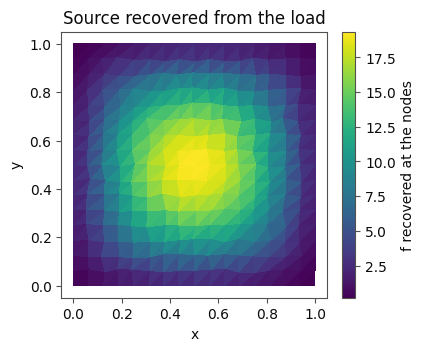
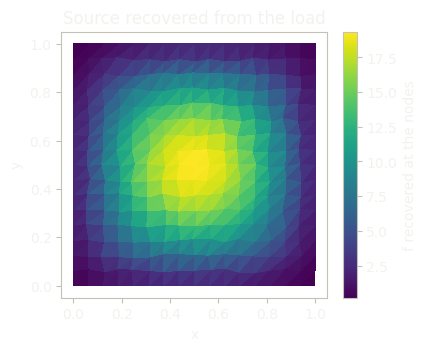

In [8]:
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

field = b / share

fig, ax = plt.subplots(figsize=(4.2, 3.4), constrained_layout=True)
mesh = mtri.Triangulation(nodes[:, 0], nodes[:, 1], conn)
shade = ax.tripcolor(mesh, field, shading="flat", cmap="viridis")
if E < 200:
    ax.triplot(mesh, lw=0.4, color="#898781")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Source recovered from the load")
fig.colorbar(shade, ax=ax, label="f recovered at the nodes")
show(fig, "Source field recovered from the assembled load on a triangle mesh of the unit square")

## What just happened

- One lane per (triangle, corner): `Grid["e", "a":3]`, with the extent of `e` given by name at run time.
- `lane.e`, `lane[0]`, `lane[-1]` and `lane.flat` read where a lane is; `xy[p, 0]` reads a named-axis table by position.
- `hawk.scatter(b)[node] += v` is the assembly. Interior nodes of this mesh touch exactly six triangles; corner nodes one or two.
- The result equals the NumPy `add.at` loop, the loads add up to the integral of `f`, and the error falls about 4 times per halving of the spacing.
- The same kernel runs on a CPU and a GPU; only the mesh size changed.

The same scatter assembles a stiffness matrix: each triangle adds a small matrix at its three nodes' rows and columns.
Next: [particle binning](08_particle_binning), where the keys are sorted and each run of equal keys is added once.